# Praktik Komputasi Sistem Kendali: Analisis & Perancangan Root Locus
**Mata Kuliah:** Sistem Kendali — Program Studi Teknik Mesin, Universitas Malikussaleh

Notebook ini menyajikan penyelesaian bertahap untuk dua studi kasus terapan menggunakan metode **Root Locus**:
1. **Studi Kasus 1 (Sistem Mekanika):** Kendali posisi meja geser presisi (*Mass-Damper System*) — penentuan penguatan proporsional ($K$) berdasarkan target rasio redaman ($\zeta$).
2. **Studi Kasus 2 (Sistem Fluida):** Kendali ketinggian air tangki bertingkat — perancangan **Kompensator Lead** menggunakan metode defisiensi sudut dan konstruksi bisektris.

> **Catatan:** Jika menjalankan notebook ini di Google Colab atau lingkungan Python baru yang belum memiliki pustaka `python-control`, hilangkan tanda pagar (`#`) pada baris instalasi di bawah ini.

In [1]:
# Jalankan baris berikut jika pustaka 'control' belum terpasang:
# !pip install control

import numpy as np
import matplotlib.pyplot as plt
import control as ct

# Konfigurasi tampilan grafik agar bersih dan mudah dibaca
plt.rcParams['figure.figsize'] = (9, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.35
plt.rcParams['font.size'] = 10

print("Pustaka siap digunakan! Versi python-control:", ct.__version__)

Pustaka siap digunakan! Versi python-control: 0.10.2


---
## Bagian 1: Studi Kasus 1 — Sistem Mekanika (Meja Geser Presisi)

### Deskripsi Masalah
Sebuah meja geser bermassa $m = 1\text{ kg}$ bergerak di atas rel berminyak dengan koefisien gesek viskos $c = 4\text{ N}\cdot\text{s/m}$. Posisi meja $x(t)$ dikendalikan oleh gaya aktuator $u(t)$ dalam konfigurasi umpan balik negatif satuan ($H(s) = 1$) dengan penguatan proporsional $K$.

**Target Desain:**
1. Menurunkan fungsi alih *open-loop* $G(s) = \frac{X(s)}{U(s)}$ dan memetakan kurva *Root Locus*-nya.
2. Menentukan koordinat titik desain $s_d$ dan nilai *Gain* $K$ agar sistem memiliki rasio redaman $\zeta = 0.5$.

### Langkah 1.1: Pemodelan Matematis & Fungsi Alih Open-Loop
Dari Hukum II Newton ($\sum F = m\ddot{x}$):
$$m\ddot{x}(t) + c\dot{x}(t) = u(t) \implies \ddot{x}(t) + 4\dot{x}(t) = u(t)$$

Dengan Transformasi Laplace (kondisi awal nol), fungsi alih sistem adalah:
$$G(s) = \frac{X(s)}{U(s)} = \frac{1}{s^2 + 4s} = \frac{1}{s(s + 4)}$$

In [2]:
# Parameter fisik sistem mekanika
m = 1.0   # massa (kg)
c = 4.0   # koefisien redaman viskos (N.s/m)

# Mendefinisikan fungsi alih open-loop G(s) = 1 / (m*s^2 + c*s)
num_1 = [1.0]
den_1 = [m, c, 0.0]
G1 = ct.TransferFunction(num_1, den_1)

poles_1 = ct.poles(G1)
zeros_1 = ct.zeros(G1)

print("Fungsi Alih Plant Mekanika G1(s):")
print(G1)
print(f"Pole Open-Loop : {poles_1}")
print(f"Zero Open-Loop : {zeros_1}")

Fungsi Alih Plant Mekanika G1(s):
<TransferFunction>: sys[0]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

      1
  ---------
  s^2 + 4 s
Pole Open-Loop : [-4.+0.j  0.+0.j]
Zero Open-Loop : []


### Langkah 1.2: Perhitungan Analitik Aturan Root Locus & Titik Target ($s_d$)
Sebelum menggambar grafik, kita hitung parameter geometrisnya secara analitik:
* **Jumlah Pole ($n$) = 2** (di $s=0$ dan $s=-4$), **Jumlah Zero ($m$) = 0**.
* **Pusat Asimtot:** $\sigma_a = \frac{(0 + (-4)) - 0}{2} = -2$.
* **Sudut Asimtot:** $\phi_a = \frac{180^\circ(2k+1)}{2} \implies 90^\circ \text{ dan } 270^\circ$.
* **Titik Pencar (*Breakaway*):** $\frac{dK}{ds} = -(2s + 4) = 0 \implies s = -2$.
* **Garis Redaman Konstan ($\zeta = 0.5$):** $\theta = \cos^{-1}(0.5) = 60^\circ$.

Karena cabang *Root Locus* bergerak vertikal lurus pada garis $\sigma = -2$, titik perpotongan dengan garis sudut $60^\circ$ adalah:
$$s_d = -2 + j\left(2 \tan 60^\circ\right) = -2 + j2\sqrt{3} \approx -2 + j3.464$$

In [3]:
# Target spesifikasi redaman
zeta_target_1 = 0.5
theta_1 = np.arccos(zeta_target_1)  # dalam radian (60 derajat)

# Pusat asimtot & titik pencar
sigma_a1 = np.sum(poles_1.real) / len(poles_1)

# Koordinat titik desain harapan s_d
sigma_d1 = sigma_a1
omega_d1 = abs(sigma_d1) * np.tan(theta_1)
sd_1 = complex(sigma_d1, omega_d1)

# Syarat Magnitudo: K = perkalian jarak dari semua pole ke s_d
L1 = abs(sd_1 - poles_1[0])
L2 = abs(sd_1 - poles_1[1])
K_desain_1 = L1 * L2

print(f"Sudut garis redaman (theta) : {np.degrees(theta_1):.2f} derajat")
print(f"Titik pencar (breakaway)    : {sigma_a1:.2f}")
print(f"Koordinat target (s_d)      : {sd_1.real:.3f} + j{sd_1.imag:.3f}")
print(f"Jarak vektor L1 dan L2      : L1 = {L1:.3f}, L2 = {L2:.3f}")
print(f"Gain Proporsional (K)       : {K_desain_1:.2f}")

Sudut garis redaman (theta) : 60.00 derajat
Titik pencar (breakaway)    : -2.00
Koordinat target (s_d)      : -2.000 + j3.464
Jarak vektor L1 dan L2      : L1 = 4.000, L2 = 4.000
Gain Proporsional (K)       : 16.00


### Langkah 1.3: Visualisasi Grafik Root Locus Sistem Mekanika
Sekarang kita plot kurva *Root Locus* beserta garis panduan rasio redaman $\zeta = 0.5$ dan posisi *pole* tertutup saat $K = 16$.

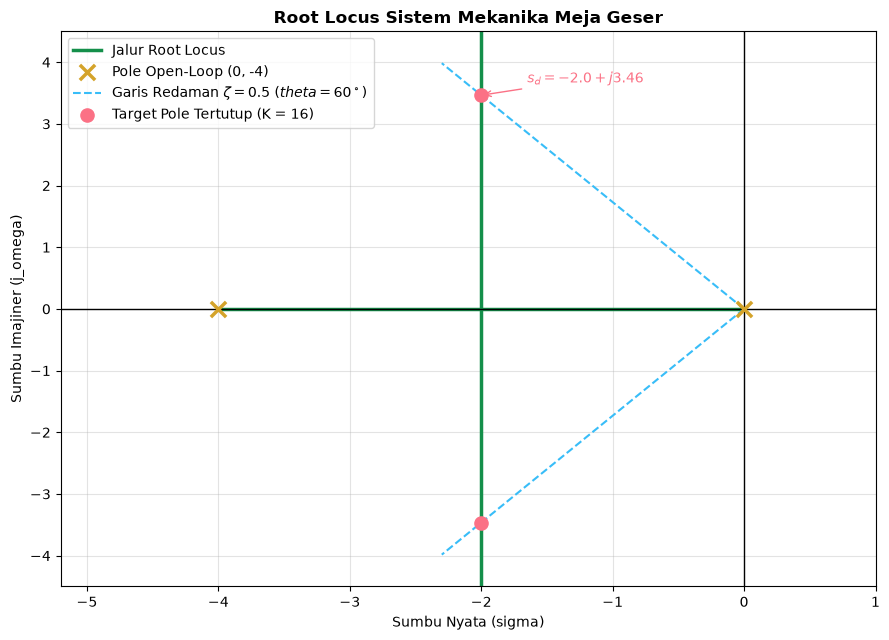

In [7]:
fig, ax = plt.subplots(figsize=(9, 6.5))

# Plot kurva Root Locus
roots_1, gains_1 = ct.root_locus(G1, plot=False)
for idx in range(roots_1.shape[1]):
    ax.plot(roots_1[:, idx].real, roots_1[:, idx].imag, color='#148F4A', linewidth=2.5,
            label='Jalur Root Locus' if idx == 0 else "")

# Tandai Pole Open-Loop (X)
ax.scatter(poles_1.real, poles_1.imag, marker='x', s=120, color='#D4A32A', linewidths=2.5, zorder=5,
           label='Pole Open-Loop (0, -4)')

# Garis redaman konstan zeta = 0.5 (60 derajat dari sumbu real negatif)
r_line = np.linspace(0, 4.6, 100)
ax.plot(-r_line * np.cos(theta_1), r_line * np.sin(theta_1), '--', color='#38BDF8', linewidth=1.5,
        label=r'Garis Redaman $\zeta = 0.5$ ($	theta = 60^\circ$)')
ax.plot(-r_line * np.cos(theta_1), -r_line * np.sin(theta_1), '--', color='#38BDF8', linewidth=1.5)

# Tandai Titik Target Desain s_d (Closed-loop poles pada K = 16)
ax.scatter([sd_1.real, sd_1.real], [sd_1.imag, -sd_1.imag], color='#FB7185', s=90, zorder=6,
           label=f'Target Pole Tertutup (K = {K_desain_1:.0f})')
ax.annotate(f'$s_d = {sd_1.real:.1f} + j{sd_1.imag:.2f}$',
            xy=(sd_1.real, sd_1.imag), xytext=(sd_1.real + 0.35, sd_1.imag + 0.2),
            color='#FB7185', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#FB7185'))

# Garis sumbu koordinat
ax.axhline(0, color='black', linewidth=1)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlim(-5.2, 1.0)
ax.set_ylim(-4.5, 4.5)
ax.set_title('Root Locus Sistem Mekanika Meja Geser', fontweight='bold')
ax.set_xlabel('Sumbu Nyata (sigma)')
ax.set_ylabel('Sumbu Imajiner (j_omega)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Langkah 1.4: Validasi Respon Undak (*Step Response*)
Mari kita uji sistem lup tertutup dengan $K = 16$ menggunakan masukan undak satuan (*unit step*) untuk memastikan apakah perilaku fisik meja geser sesuai dengan teori.

<>:15: SyntaxWarning: invalid escape sequence '\z'
<>:15: SyntaxWarning: invalid escape sequence '\z'
/tmp/ipykernel_23874/2502443647.py:15: SyntaxWarning: invalid escape sequence '\z'
  plt.title('Validasi Step Response Sistem Mekanika ($\zeta = 0.5$)', fontweight='bold')


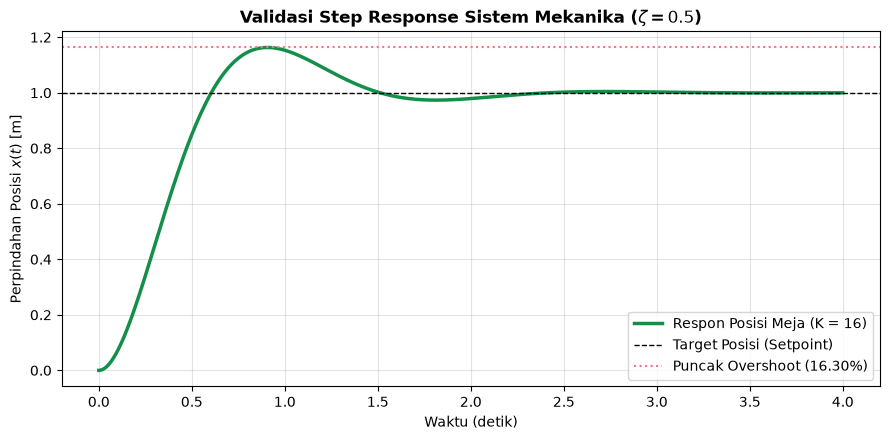

=== Ringkasan Performa Sistem Mekanika (K = 16) ===
Maximum Overshoot : 16.30% (Teoretis zeta=0.5: 16.30%)
Settling Time (2%): 2.02 detik (Teoretis 4/|sigma_d|: 2.00 detik)
Steady-State Value: 0.9997 m (Error tunak = 0)


In [12]:
# Membentuk sistem lup tertutup T1(s) = (K * G1) / (1 + K * G1)
T1 = ct.feedback(K_desain_1 * G1, 1)

# Simulasi respon waktu selama 4 detik
t1 = np.linspace(0, 4, 500)
t1, y1 = ct.step_response(T1, T=t1)
info_1 = ct.step_info(T1)

plt.figure(figsize=(9, 4.5))
plt.plot(t1, y1, color='#148F4A', linewidth=2.5, label=f'Respon Posisi Meja (K = {K_desain_1:.0f})')
plt.axhline(1.0, color='black', linestyle='--', linewidth=1, label='Target Posisi (Setpoint)')
plt.axhline(1.0 + info_1['Overshoot']/100.0, color='#FB7185', linestyle=':', linewidth=1.5,
            label=f"Puncak Overshoot ({info_1['Overshoot']:.2f}%)")

plt.title('Validasi Step Response Sistem Mekanika ($\zeta = 0.5$)', fontweight='bold')
plt.xlabel('Waktu (detik)')
plt.ylabel('Perpindahan Posisi $x(t)$ [m]')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("=== Ringkasan Performa Sistem Mekanika (K = 16) ===")
print(f"Maximum Overshoot : {info_1['Overshoot']:.2f}% (Teoretis zeta=0.5: 16.30%)")
print(f"Settling Time (2%): {info_1['SettlingTime']:.2f} detik (Teoretis 4/|sigma_d|: 2.00 detik)")
print(f"Steady-State Value: {y1[-1]:.4f} m (Error tunak = 0)")

---
## Bagian 2: Studi Kasus 2 — Sistem Fluida (Tangki Bertingkat Non-Interaksi)

### Deskripsi Masalah
Dua buah tangki fluida dipasang seri tanpa interaksi balik:
* **Tangki 1:** Resistansi katup $R_1 = 1\text{ s/m}^2$, luas penampang $C_1 = 1\text{ m}^2 \implies \tau_1 = R_1 C_1 = 1\text{ s}$.
* **Tangki 2:** Resistansi katup $R_2 = 0.5\text{ s/m}^2$, luas penampang $C_2 = 1\text{ m}^2 \implies \tau_2 = R_2 C_2 = 0.5\text{ s}$.

Fungsi alih gabungan antara debit masuk $Q_{\text{in}}(s)$ dan ketinggian air tangki kedua $H_2(s)$ adalah:
$$G(s) = \frac{H_2(s)}{Q_{\text{in}}(s)} = \left(\frac{1}{s+1}\right)\left(\frac{1}{s+2}\right) = \frac{1}{(s+1)(s+2)}$$

**Misi Perancangan:**
Klien menginginkan respon ketinggian air yang jauh lebih cepat dengan menargetkan kutub dominan lup tertutup di **$s_d = -3 + j3$**. Karena jalur *Root Locus* asli hanya bergerak di garis vertikal $\sigma = -1.5$, kita harus merancang **Kompensator Lead** $G_c(s) = K_c\frac{s + z_c}{s + p_c}$ menggunakan metode bisektris.

In [13]:
# Mendefinisikan fungsi alih tangki fluida G2(s) = 1 / ((s+1)(s+2))
G2 = ct.TransferFunction([1.0], np.polymul([1.0, 1.0], [1.0, 2.0]))
poles_2 = ct.poles(G2)

# Titik target desain klien
sd_2 = complex(-3.0, 3.0)

print("Fungsi Alih Sistem Fluida G2(s):")
print(G2)
print(f"Pole Open-Loop Asli : {poles_2}")
print(f"Titik Target Desain  : {sd_2}")

Fungsi Alih Sistem Fluida G2(s):
<TransferFunction>: sys[36]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

        1
  -------------
  s^2 + 3 s + 2
Pole Open-Loop Asli : [-2.+0.j -1.+0.j]
Titik Target Desain  : (-3+3j)


### Langkah 2.1: Audit Defisiensi Sudut ($\phi$) & Konstruksi Metode Bisektris
Untuk memaksa kurva *Root Locus* berbelok melewati $s_d = -3 + j3$, kita hitung sudut yang disumbangkan oleh kedua *pole* asli ke titik $s_d$, lalu mencari kekurangan sudut ($\phi$) agar memenuhi Syarat Sudut ($180^\circ$):
$$\phi = 180^\circ - \left(\sum \angle \text{Zero} - \sum \angle \text{Pole}\right)$$

Selanjutnya, kita terapkan langkah geometris **Metode Bisektris** dari titik $s_d(-3, 3)$:
1. Sudut garis mendatar ke kiri $= 180^\circ$.
2. Sudut garis dari $s_d(-3, 3)$ menuju titik origin $(0,0) = 315^\circ$.
3. Sudut garis bisektris $= \frac{180^\circ + 315^\circ}{2} = 247.5^\circ$.
4. Sebarkan $\frac{\phi}{2}$ ke kanan garis bisektris untuk menentukan posisi $-z_c$, dan $\frac{\phi}{2}$ ke kiri garis bisektris untuk posisi $-p_c$.

In [14]:
# 1. Hitung sudut vektor dari masing-masing pole asli ke s_d = -3 + j3
theta_p1 = np.degrees(np.angle(sd_2 - poles_2[0]))  # dari s = -1
theta_p2 = np.degrees(np.angle(sd_2 - poles_2[1]))  # dari s = -2

# 2. Defisiensi sudut phi (dalam rentang 0 - 360 derajat)
phi_deg = (180.0 - (0.0 - (theta_p1 + theta_p2))) % 360.0

# 3. Metode Bisektris dari titik s_d(-3, 3)
ang_horizontal = 180.0
ang_to_origin = np.degrees(np.angle(complex(0, 0) - sd_2)) % 360.0  # 315 derajat
ang_bisector = 0.5 * (ang_horizontal + ang_to_origin)               # 247.5 derajat

# Arah sinar dari s_d menuju sumbu nyata untuk z_c dan p_c
ang_ray_zc = ang_bisector + 0.5 * phi_deg
ang_ray_pc = ang_bisector - 0.5 * phi_deg

# Perpotongan masing-masing sinar dengan sumbu nyata (Im(s) = 0)
# Rumus parametrik: y(t) = y_d + t * sin(ang) = 0  =>  t = -y_d / sin(ang)
t_zc = -sd_2.imag / np.sin(np.radians(ang_ray_zc))
t_pc = -sd_2.imag / np.sin(np.radians(ang_ray_pc))

pos_zc = sd_2.real + t_zc * np.cos(np.radians(ang_ray_zc))  # koordinat negatif (-z_c)
pos_pc = sd_2.real + t_pc * np.cos(np.radians(ang_ray_pc))  # koordinat negatif (-p_c)

zc = -pos_zc
pc = -pos_pc

# 4. Syarat Magnitudo untuk menghitung Penguatan Kompensator K_c
Lz = abs(sd_2 - pos_zc)
Lp1 = abs(sd_2 - poles_2[0])
Lp2 = abs(sd_2 - poles_2[1])
Lpc = abs(sd_2 - pos_pc)

Kc = (Lp1 * Lp2 * Lpc) / Lz

print(f"Sudut dari pole -1 (theta_1) : {theta_p1:.2f} deg")
print(f"Sudut dari pole -2 (theta_2) : {theta_p2:.2f} deg")
print(f"Defisiensi sudut (phi)       : {phi_deg:.2f} deg")
print("-" * 48)
print(f"Letak Zero Kompensator (-z_c): {pos_zc:.3f}  => z_c = {zc:.3f}")
print(f"Letak Pole Kompensator (-p_c): {pos_pc:.3f}  => p_c = {pc:.3f}")
print(f"Penguatan Kompensator (K_c)  : {Kc:.3f}")

# Bentuk objek Transfer Function Kompensator Lead
Gc_lead = ct.TransferFunction([Kc, Kc * zc], [1.0, pc])
print("\nFungsi Alih Kompensator Lead Gc(s):")
print(Gc_lead)

Sudut dari pole -1 (theta_1) : 108.43 deg
Sudut dari pole -2 (theta_2) : 123.69 deg
Defisiensi sudut (phi)       : 52.13 deg
------------------------------------------------
Letak Zero Kompensator (-z_c): -2.813  => z_c = 2.813
Letak Pole Kompensator (-p_c): -6.398  => p_c = 6.398
Penguatan Kompensator (K_c)  : 17.195

Fungsi Alih Kompensator Lead Gc(s):
<TransferFunction>: sys[37]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  17.2 s + 48.37
  --------------
    s + 6.398


### Langkah 2.2: Visualisasi Perbandingan Root Locus (Sebelum vs Sesudah Kompensasi)
Grafik di bawah ini memperlihatkan secara visual bagaimana penambahan pasangan *zero* ($-2.81$) dan *pole* ($-6.40$) berhasil menarik lintasan *Root Locus* ke arah kiri sehingga melintasi titik target $s_d = -3 \pm j3$.

<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_23874/3380139557.py:31: SyntaxWarning: invalid escape sequence '\s'
  ax2.axvline(-1.5, color='#71717A', linestyle=':', linewidth=1.2, label='Jalur Lama ($\sigma=-1.5$)')


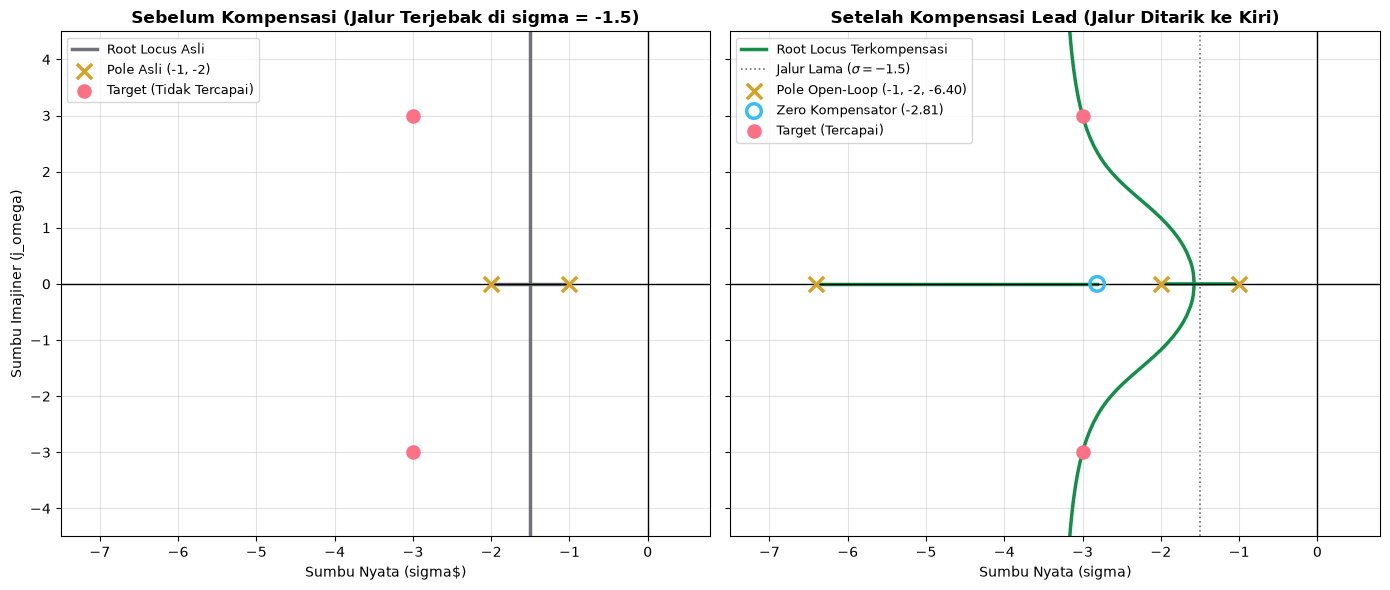

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# --- SUBPLOT 1: SISTEM ASLI (TANPA KOMPENSATOR) ---
roots_orig, _ = ct.root_locus(G2, plot=False)
for idx in range(roots_orig.shape[1]):
    ax1.plot(roots_orig[:, idx].real, roots_orig[:, idx].imag, color='#71717A', linewidth=2.5,
             label='Root Locus Asli' if idx == 0 else "")

ax1.scatter(poles_2.real, poles_2.imag, marker='x', s=120, color='#D4A32A', linewidths=2.5, zorder=5,
            label='Pole Asli (-1, -2)')
ax1.scatter([sd_2.real, sd_2.real], [sd_2.imag, -sd_2.imag], color='#FB7185', s=90, zorder=6,
            label='Target (Tidak Tercapai)')

ax1.axhline(0, color='black', linewidth=1)
ax1.axvline(0, color='black', linewidth=1)
ax1.set_xlim(-7.5, 0.8)
ax1.set_ylim(-4.5, 4.5)
ax1.set_title('Sebelum Kompensasi (Jalur Terjebak di sigma = -1.5)', fontweight='bold')
ax1.set_xlabel('Sumbu Nyata (sigma$)')
ax1.set_ylabel('Sumbu Imajiner (j_omega)')
ax1.legend(loc='upper left', fontsize=9)

# --- SUBPLOT 2: SISTEM TERKOMPENSASI LEAD ---
G2_comp = Gc_lead * G2
roots_comp, _ = ct.root_locus(G2_comp, plot=False)
for idx in range(roots_comp.shape[1]):
    ax2.plot(roots_comp[:, idx].real, roots_comp[:, idx].imag, color='#148F4A', linewidth=2.5,
             label='Root Locus Terkompensasi' if idx == 0 else "")

# Jalur lama sebagai pembanding
ax2.axvline(-1.5, color='#71717A', linestyle=':', linewidth=1.2, label='Jalur Lama ($\sigma=-1.5$)')

# Tandai semua pole & zero terbuka
all_poles_2 = ct.poles(G2_comp)
ax2.scatter(all_poles_2.real, all_poles_2.imag, marker='x', s=120, color='#D4A32A', linewidths=2.5, zorder=5,
            label='Pole Open-Loop (-1, -2, -6.40)')
ax2.scatter([pos_zc], [0], marker='o', s=110, facecolors='none', edgecolors='#38BDF8', linewidths=2.5, zorder=5,
            label='Zero Kompensator (-2.81)')

# Tandai titik target s_d yang kini terlewati
ax2.scatter([sd_2.real, sd_2.real], [sd_2.imag, -sd_2.imag], color='#FB7185', s=90, zorder=6,
            label='Target (Tercapai)')

ax2.axhline(0, color='black', linewidth=1)
ax2.axvline(0, color='black', linewidth=1)
ax2.set_xlim(-7.5, 0.8)
ax2.set_title('Setelah Kompensasi Lead (Jalur Ditarik ke Kiri)', fontweight='bold')
ax2.set_xlabel('Sumbu Nyata (sigma)')
ax2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

### Langkah 2.3: Verifikasi Lokasi Kutub Tertutup & Perbandingan Step Response
Terakhir, kita periksa lokasi akar persamaan karakteristik lup tertutup setelah kompensasi dan membandingkan kecepatan pengisian tangki fluida sebelum dan sesudah dipasang kompensator *Lead*.

Akar Lup Tertutup Tanpa Kompensator (K=2.5) : [-1.5+1.5j -1.5-1.5j]
Akar Lup Tertutup Dengan Lead Compensator   : [-3.   +3.j -3.   -3.j -3.398+0.j]


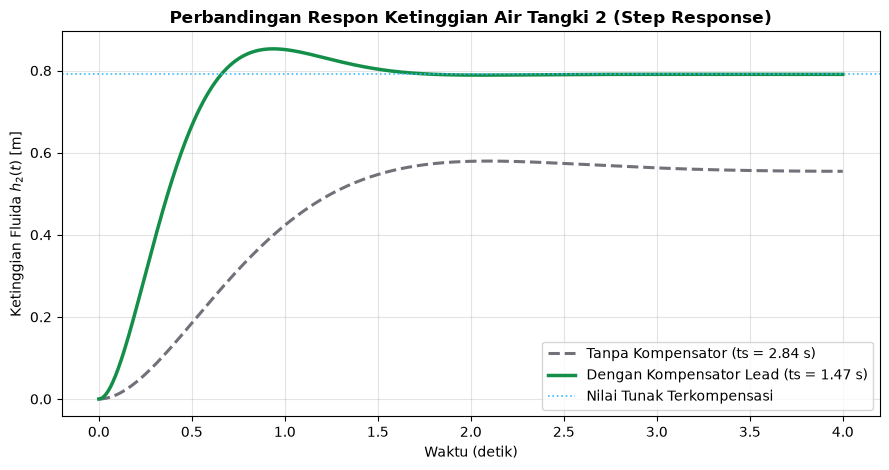


=== Perbandingan Performa Transien Sistem Fluida ===
Settling Time Tanpa Kompensator : 2.84 detik
Settling Time Dengan Lead       : 1.47 detik (2x lebih cepat!)
Overshoot Dengan Lead           : 7.86%


In [22]:
# Sistem tertutup terkompensasi (umpan balik satuan)
T2_comp = ct.feedback(G2_comp, 1)

# Sebagai pembanding: sistem tanpa kompensator dengan gain yang memberi zeta sama (zeta = 0.707)
# Pada garis sigma = -1.5, sudut 45 deg => s_d_lama = -1.5 + j1.5 => K_lama = |-0.5+j1.5|*|0.5+j1.5| = 2.5
K_lama = 2.5
T2_orig = ct.feedback(K_lama * G2, 1)

# Cek akar lup tertutup aktual
print("Akar Lup Tertutup Tanpa Kompensator (K=2.5) :", np.round(ct.poles(T2_orig), 3))
print("Akar Lup Tertutup Dengan Lead Compensator   :", np.round(ct.poles(T2_comp), 3))

# Simulasi Step Response selama 4 detik
t2 = np.linspace(0, 4, 500)
_, y2_orig = ct.step_response(T2_orig, T=t2)
_, y2_comp = ct.step_response(T2_comp, T=t2)

info_2_orig = ct.step_info(T2_orig)
info_2_comp = ct.step_info(T2_comp)

plt.figure(figsize=(9, 4.8))
plt.plot(t2, y2_orig, '--', color='#71717A', linewidth=2.2,
         label=f"Tanpa Kompensator (ts = {info_2_orig['SettlingTime']:.2f} s)")
plt.plot(t2, y2_comp, color='#148F4A', linewidth=2.5,
         label=f"Dengan Kompensator Lead (ts = {info_2_comp['SettlingTime']:.2f} s)")
plt.axhline(y2_comp[-1], color='#38BDF8', linestyle=':', linewidth=1.2, label='Nilai Tunak Terkompensasi')

plt.title('Perbandingan Respon Ketinggian Air Tangki 2 (Step Response)', fontweight='bold')
plt.xlabel('Waktu (detik)')
plt.ylabel('Ketinggian Fluida $h_2(t)$ [m]')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("\n=== Perbandingan Performa Transien Sistem Fluida ===")
print(f"Settling Time Tanpa Kompensator : {info_2_orig['SettlingTime']:.2f} detik")
print(f"Settling Time Dengan Lead       : {info_2_comp['SettlingTime']:.2f} detik (2x lebih cepat!)")
print(f"Overshoot Dengan Lead           : {info_2_comp['Overshoot']:.2f}%")